# Hypothesis Testing

## 1. Imports


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import ttest_ind, f_oneway, chi2_contingency, mannwhitneyu, kruskal
import warnings
from helper_functions import separator
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_parquet('../data/generated/sales_data.parquet', engine = 'pyarrow')
df['date'] = pd.to_datetime(df['date'])
print(f"Dataset: {df.shape[0]:,} rows x {df.shape[1]:,} cols")

Dataset: 2,923,245 rows x 55 cols


## 2. GROUP A: STORE PERFORMANCE HYPOTHESES

### H1. Does Parking Increase Sales ?

H0: Parking Availability has no effect on sales <br>
H1: Parking increases sales (especially for Electronics)

In [3]:
# Overall
with_parking = df[df['parking_available'] == 1]['sales_qty']
without_parking = df[df['parking_available'] == 0]['sales_qty']

t_stat, p_value = ttest_ind(with_parking, without_parking)

print("\nOverall:")
print(f"    With parking: Mean = {with_parking.mean():.2f}, Std Deviation: = {with_parking.std():.2f}")
print(f"    Without parking: Mean= {without_parking.mean():.2f}, Std Deviation = {without_parking.mean():.2f}")
print(f"    t-statistic: {t_stat:.4f}, p-value: {p_value:.6f}")

if p_value < 0.05:
    print(f"    REJECT H0: Parking increases sales (p < 0.05)")
    effect_size = (with_parking.mean() - without_parking.mean()) / np.sqrt(((len(with_parking) - 1)*with_parking.std()**2 +(len(without_parking)-1)* without_parking.std()**2) / (len(with_parking) + len(without_parking) - 2))
    print(f"    Effect size (Cohen's d): {effect_size:.3f}")

else:
    print(f"    FAIL TO REJECT H0: No significant parking effect")

# By Category (Does parking matter more for electronics ?)
print("\nBy Category")
for category in df['category'].unique():
    cat_data = df[df['category'] == category]
    with_p = cat_data[cat_data['parking_available'] == 1]['sales_qty']
    without_p = cat_data[cat_data['parking_available'] == 0]['sales_qty']

    t, p = ttest_ind(with_p, without_p)
    print(f"    {category}: p = {p:.6f} {'SIGNIFICANT' if p < 0.05 else 'Not Significant'}")



Overall:
    With parking: Mean = 60.16, Std Deviation: = 64.19
    Without parking: Mean= 44.24, Std Deviation = 44.24
    t-statistic: 151.8670, p-value: 0.000000
    REJECT H0: Parking increases sales (p < 0.05)
    Effect size (Cohen's d): 0.255

By Category
    Electronics: p = 0.000000 SIGNIFICANT
    Clothing: p = 0.000000 SIGNIFICANT
    Grocery: p = 0.000000 SIGNIFICANT


### H2: Do mall Stores outperform street stores?

H0: Mall stores have the same revenue as street stores <br>
H1: Mall stores have higher revenue

H2: Do Mall Stores outperform Street Stores?

Mall stores: Mean = 30,524,744,511, Std Deviation = Rs.9,331,235,931
Street Stores: Mean = 18,062,632,604, Std. Deviation = Rs.5,320,860,880
t-statistic: 5.1703, p_value: 0.000010
REJECT H0: Mall stores significantly outperform (p < 0.05)
Effect Size (Cohen's d): 1.731
Uplift: 69.0%


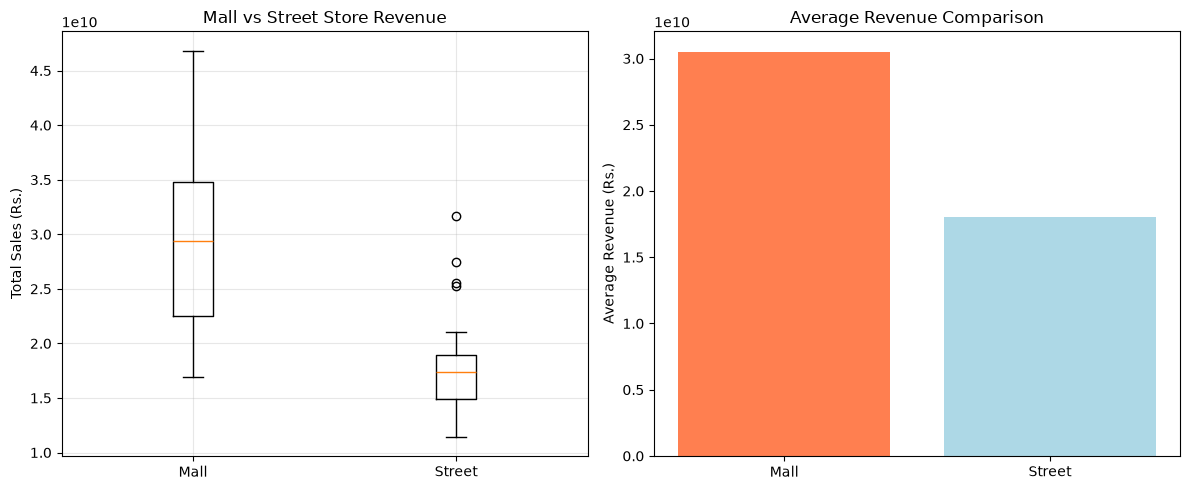

In [7]:
separator()
print("H2: Do Mall Stores outperform Street Stores?")
separator()

mall = df[df['in_mall'] == 1].groupby('store_id')['sales'].sum()
street = df[df['in_mall'] == 0].groupby('store_id')['sales'].sum()

t_stat, p_value = ttest_ind(mall, street)

print(f"\nMall stores: Mean = {mall.mean():,.0f}, Std Deviation = Rs.{mall.std():,.0f}")
print(f"Street Stores: Mean = {street.mean():,.0f}, Std. Deviation = Rs.{street.std():,.0f}")
print(f"t-statistic: {t_stat:.4f}, p_value: {p_value:.6f}")

if p_value < 0.05:
    print(f"REJECT H0: Mall stores significantly outperform (p < 0.05)")
    effect_size = (mall.mean() - street.mean()) / np.sqrt(((len(mall) - 1)*mall.std()**2 + (len(street)-1)*street.std()**2)/ (len(mall) + len(street) -2))
    print(f"Effect Size (Cohen's d): {effect_size:.3f}")
    print(f"Uplift: {((mall.mean() / street.mean() -1)*100):.1f}%")
else:
    print(f"FAIL TO REJECT H0")

# Visualization
fig, ax = plt.subplots(1, 2, figsize = (12, 5))
ax[0].boxplot([mall, street], tick_labels=['Mall', 'Street'])
ax[0].set_ylabel('Total Sales (Rs.)')
ax[0].set_title('Mall vs Street Store Revenue')
ax[0].grid(True, alpha = 0.3)

ax[1].bar(['Mall', 'Street'], [mall.mean(), street.mean()], color = ['coral', 'lightblue'])
ax[1].set_ylabel('Average Revenue (Rs.)')
ax[1].set_title('Average Revenue Comparison')
plt.tight_layout()
plt.show()

### H3: Do Premium Stores Sell More?

H0: Premium store flag has no effect on sales <br>
H1: Premium stores hae higher sales

In [8]:
separator()
print("H3: Do Premium stores sell more?")
separator()

premium = df[df['premium_store_flag'] == 1]['sales']
non_premium = df[df['premium_store_flag'] == 0]['sales']

t_stat, p_value = ttest_ind(premium, non_premium)

print(f"\nPremium Stores: Mean = Rs.{premium.mean():,.0f}, Standard Deviation = Rs.{premium.std():,.0f}")
print(f"Non-Premium: Mean = Rs.{non_premium.mean():,.0f}, Standard Deviation = Rs.{non_premium.std():,.0f}")
print(f"t-statistic: {t_stat:.4f}, p-value: {p_value:.6f}")

if p_value < 0.05:
    print("REJECT H0: Premium stores sell significantly more (p < 0.05)")
else:
    print(f"FAIL TO REJECT H0")

H3: Do Premium stores sell more?

Premium Stores: Mean = Rs.424,135, Standard Deviation = Rs.664,870
Non-Premium: Mean = Rs.246,556, Standard Deviation = Rs.403,505
t-statistic: 274.3171, p-value: 0.000000
REJECT H0: Premium stores sell significantly more (p < 0.05)
